In [1]:
# load all the files from colab temp loading

# Load Phase 2 outputs + label missed batch events

In [2]:
# upload and load phase 2 files
import pandas as pd
import numpy as np
from collections import deque

full_log  = pd.read_csv("greedy_dispatch_log.csv")
orders    = pd.read_csv("orders.csv")
districts = pd.read_csv("districts.csv")

In [3]:
# enriching orders and merging with dispatch log

# it merges 3 files into 1
# greedy_dispatch_log.csv → knows what happened (who delivered, how far, when dispatched) but nothing about the order itself
# orders.csv → knows order details (restaurant, SLA, peak window) but not what the dispatcher did
# districts.csv → knows coordinates of each zone
# so it mergres them so we can use the combined data later in below steps more efficiently and can make further steps more easier

orders["hour"] = (orders["timestamp_sec"] // 3600) % 24

# Join delivery coordinates from districts
orders_enriched = orders.merge(
    districts[["district_id", "centroid_lat", "centroid_lon"]],
    left_on="destination_zone_id", right_on="district_id", how="left"
).rename(columns={"centroid_lat": "delivery_lat", "centroid_lon": "delivery_lon"})

# Merge all useful order fields onto the dispatch log, sorted by dispatch time
KEEP_COLS = [
    "order_id", "restaurant_id", "destination_zone_id",
    "peak_window", "hour", "sla_deadline_sec", "estimated_ready_sec",
    "delivery_lat", "delivery_lon"
]

dispatch_info = full_log.merge(
    orders_enriched[KEEP_COLS], on="order_id", how="left"
).sort_values("dispatch_time").reset_index(drop=True)

print("dispatch_info shape:", dispatch_info.shape)
print("\nFirst 3 rows:")
print(dispatch_info[["order_id", "restaurant_id", "assigned_partner",
                      "dispatch_time", "peak_window", "hour"]].head(5))

dispatch_info shape: (1515, 15)

First 3 rows:
   order_id restaurant_id assigned_partner  dispatch_time peak_window  hour
0  O-000024       R-S-040          R-S-005          36050     offpeak    10
1  O-000006       R-L-059          R-L-048          36233     offpeak    10
2  O-000050       R-L-068          R-L-050          36235     offpeak    10
3  O-000053       R-L-053          R-S-050          36388     offpeak    10
4  O-000002       R-L-010          R-M-005          36447     offpeak    10


In [4]:
#  checks and stores whether the multiple orders from the same restaurent were sent seperately where they could have been batched

WINDOW_SEC = 120  # anchored BATCH_WINDOW_SEC value from Build_City_Network / Greedy_Baseline

missed_order_ids = set()          # will hold both orders in every missed pair
recent_by_restaurant = {}         # restaurant_id → deque of recent dispatches

for _, row in dispatch_info.iterrows():
    rid     = row["restaurant_id"]
    t       = row["dispatch_time"]
    oid     = row["order_id"]
    partner = row["assigned_partner"]

    dq = recent_by_restaurant.setdefault(rid, deque())

    # Evict entries that have fallen outside the 90-second window
    while dq and t - dq[0][1] > WINDOW_SEC:
        dq.popleft()

    # Missed batch = same restaurant, within window, different partner
    if pd.notna(partner):
        for prev_oid, prev_t, prev_partner in dq:
            if pd.notna(prev_partner) and prev_partner != partner:
                missed_order_ids.add(prev_oid)   # earlier order: should have waited
                missed_order_ids.add(oid)         # current order: partner shouldn't have been sent

    dq.append((oid, t, partner))

print(f"Unique order IDs involved in a missed batch: {len(missed_order_ids)}")
print(f"(Compare against Greedy_Baseline's missed_batch_count on the officially sourced dataset)")

Unique order IDs involved in a missed batch: 50
(Compare against Greedy_Baseline's missed_batch_count on the officially sourced dataset)


In [5]:
# Attach label, verify distribution, save

import os

# 1 = should have waited (missed batch opportunity), 0 = correct greedy dispatch
dispatch_info["missed_batch_label"] = (
    dispatch_info["order_id"].isin(missed_order_ids).astype(int)
)

# ── Sanity check 1: overall label counts ─────────────────────────────────────
label_counts = dispatch_info["missed_batch_label"].value_counts()
pos_pct = label_counts.get(1, 0) / len(dispatch_info) * 100
print("Label distribution:")
print(label_counts.to_string())
print(f"\nPositive class (missed batch): {pos_pct:.2f}%")

# ── Sanity check 2: positives should be denser during lunch & dinner ─────────
print("\nMissed-batch rate by peak_window:")
print(
    dispatch_info.groupby("peak_window")["missed_batch_label"]
    .mean().mul(100).round(2).rename("missed_%").to_string()
)

# ── Save ──────────────────────────────────────────────────────────────────────
os.makedirs("results", exist_ok=True)
out_path = "results/dispatch_labeled.csv"
dispatch_info.to_csv(out_path, index=False)

print(f"\n✅ Saved → {out_path}")
print(f"   Shape  : {dispatch_info.shape}")
print(f"   Columns: {dispatch_info.columns.tolist()}")

Label distribution:
missed_batch_label
0    1465
1      50

Positive class (missed batch): 3.30%

Missed-batch rate by peak_window:
peak_window
dinner     4.20
lunch      4.07
offpeak    2.16

✅ Saved → results/dispatch_labeled.csv
   Shape  : (1515, 16)
   Columns: ['order_id', 'assigned_partner', 'pickup_distance_km', 'delivery_distance_km', 'travel_time_sec', 'dispatch_time', 'total_distance_km', 'restaurant_id', 'destination_zone_id', 'peak_window', 'hour', 'sla_deadline_sec', 'estimated_ready_sec', 'delivery_lat', 'delivery_lon', 'missed_batch_label']


# Building Features

In [6]:
LUNCH_HOURS  = [12, 13]
DINNER_HOURS = [19, 20, 21]
PEAK_HOURS   = LUNCH_HOURS + DINNER_HOURS

# time_of_day: readable time bucket for each dispatch
def label_time_of_day(hour):
    if hour in LUNCH_HOURS:
        return "lunch"
    elif hour in DINNER_HOURS:
        return "dinner"
    elif 6 <= hour < 12:
        return "morning"
    elif 14 <= hour < 19:
        return "afternoon"
    else:
        return "night"

dispatch_info["time_of_day"]  = dispatch_info["hour"].apply(label_time_of_day)

# is_peak_hour: simple binary — 1 during lunch/dinner, 0 otherwise
dispatch_info["is_peak_hour"] = dispatch_info["hour"].isin(PEAK_HOURS).astype(int)

print("time_of_day distribution:")
print(dispatch_info["time_of_day"].value_counts().to_string())

print("\nis_peak_hour distribution:")
print(dispatch_info["is_peak_hour"].value_counts().to_string())

time_of_day distribution:
time_of_day
dinner       524
afternoon    367
lunch        344
night        159
morning      121

is_peak_hour distribution:
is_peak_hour
1    868
0    647


In [7]:
# Count total orders per restaurant per peak_window
freq_map = (
    dispatch_info
    .groupby(["restaurant_id", "peak_window"])["order_id"]
    .count()
    .rename("restaurant_order_freq")
    .reset_index()
)

# Attach back to dispatch_info
dispatch_info = dispatch_info.merge(
    freq_map, on=["restaurant_id", "peak_window"], how="left"
)

print("restaurant_order_freq stats:")
print(dispatch_info["restaurant_order_freq"].describe().round(2).to_string())

restaurant_order_freq stats:
count    1515.00
mean        4.56
std         2.75
min         1.00
25%         2.00
50%         4.00
75%         6.00
max        14.00


In [8]:
WINDOW_SEC = 120  # anchored BATCH_WINDOW_SEC value

queue_depths = []
recent_by_restaurant = {}

for _, row in dispatch_info.iterrows():
    rid = row["restaurant_id"]
    t   = row["dispatch_time"]

    dq = recent_by_restaurant.setdefault(rid, deque())

    # Evict entries older than the window
    while dq and t - dq[0] > WINDOW_SEC:
        dq.popleft()

    # Depth = how many orders are currently in the window before this one
    queue_depths.append(len(dq))

    dq.append(t)


dispatch_info["queue_depth_at_restaurant"] = queue_depths

print("queue_depth_at_restaurant stats:")
print(dispatch_info["queue_depth_at_restaurant"].describe().round(2).to_string())

print("\nDepth distribution:")
print(dispatch_info["queue_depth_at_restaurant"].value_counts().sort_index().to_string())

queue_depth_at_restaurant stats:
count    1515.00
mean        0.02
std         0.13
min         0.00
25%         0.00
50%         0.00
75%         0.00
max         1.00

Depth distribution:
queue_depth_at_restaurant
0    1490
1      25


In [9]:
zone_partner_map = (
    dispatch_info[dispatch_info["assigned_partner"].notna()]
    .groupby(["destination_zone_id", "peak_window"])["assigned_partner"]
    .nunique()
    .rename("zone_partner_count")
    .reset_index()
)

dispatch_info = dispatch_info.merge(
    zone_partner_map, on=["destination_zone_id", "peak_window"], how="left"
)

# Fill zones where no partner was ever assigned
dispatch_info["zone_partner_count"] = dispatch_info["zone_partner_count"].fillna(0).astype(int)

print("zone_partner_count stats:")
print(dispatch_info["zone_partner_count"].describe().round(2).to_string())

zone_partner_count stats:
count    1515.00
mean       47.81
std        16.42
min         4.00
25%        41.00
50%        50.00
75%        68.00
max        68.00


In [10]:
from math import radians, sin, cos, sqrt, atan2

def haversine_km(lat1, lon1, lat2, lon2):
    """Straight-line distance in km between two lat/lon points."""
    R = 6371
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))

WINDOW_SEC = 120  # anchored BATCH_WINDOW_SEC value

avg_distances   = []
recent_by_restaurant = {}   # restaurant_id → deque of (dispatch_time, lat, lon)

for _, row in dispatch_info.iterrows():
    rid  = row["restaurant_id"]
    t    = row["dispatch_time"]
    lat  = row["delivery_lat"]
    lon  = row["delivery_lon"]

    dq = recent_by_restaurant.setdefault(rid, deque())

    # Evict old entries
    while dq and t - dq[0][0] > WINDOW_SEC:
        dq.popleft()

    # Average distance to all currently queued orders from same restaurant
    if len(dq) == 0:
        avg_distances.append(0.0)   # no queued orders → distance is 0
    else:
        distances = [haversine_km(lat, lon, q_lat, q_lon) for _, q_lat, q_lon in dq]
        avg_distances.append(round(sum(distances) / len(distances), 3))

    dq.append((t, lat, lon))

dispatch_info["delivery_distance_to_queued_orders"] = avg_distances

print("delivery_distance_to_queued_orders stats:")
print(dispatch_info["delivery_distance_to_queued_orders"].describe().round(3).to_string())

delivery_distance_to_queued_orders stats:
count    1515.000
mean        0.020
std         0.305
min         0.000
25%         0.000
50%         0.000
75%         0.000
max         5.833


In [11]:
FEATURE_COLS = [
    "time_of_day",
    "is_peak_hour",
    "restaurant_order_freq",
    "queue_depth_at_restaurant",
    "zone_partner_count",
    "delivery_distance_to_queued_orders",
]

# Confirm no nulls in any feature
print("Null check:")
print(dispatch_info[FEATURE_COLS].isnull().sum().to_string())

# Quick correlation of numeric features vs label
numeric_features = [f for f in FEATURE_COLS if f != "time_of_day"]
print("\nCorrelation with missed_batch_label:")
print(
    dispatch_info[numeric_features + ["missed_batch_label"]]
    .corr()["missed_batch_label"]
    .drop("missed_batch_label")
    .round(3)
    .to_string()
)

# Save
out_path = "results/dispatch_featured.csv"
dispatch_info.to_csv(out_path, index=False)

print(f"\n✅ Saved → {out_path}")

Null check:
time_of_day                           0
is_peak_hour                          0
restaurant_order_freq                 0
queue_depth_at_restaurant             0
zone_partner_count                    0
delivery_distance_to_queued_orders    0

Correlation with missed_batch_label:
is_peak_hour                          0.055
restaurant_order_freq                 0.043
queue_depth_at_restaurant             0.701
zone_partner_count                   -0.014
delivery_distance_to_queued_orders    0.352

✅ Saved → results/dispatch_featured.csv


# Training XGBoost classifier

In [12]:
import pandas as pd
import numpy as np
import os

os.makedirs("results", exist_ok=True)

dispatch_featured = pd.read_csv("results/dispatch_featured.csv")

time_of_day_map = {
    "morning"   : 0,
    "lunch"     : 1,
    "afternoon" : 2,
    "dinner"    : 3,
    "night"     : 4,
}

# Create the encoded column first before anything else
dispatch_featured["time_of_day_encoded"] = dispatch_featured["time_of_day"].map(time_of_day_map)

FEATURE_COLS = [
    "is_peak_hour",
    "restaurant_order_freq",
    "queue_depth_at_restaurant",
    "zone_partner_count",
    "delivery_distance_to_queued_orders",
    "time_of_day_encoded",
]

X = dispatch_featured[FEATURE_COLS]
y = dispatch_featured["missed_batch_label"]

print("Feature matrix shape (X):", X.shape)
print("Label distribution (y):")
print(y.value_counts().to_string())
print(f"\nPositive class (missed batch): {y.mean()*100:.2f}%")
print(f"\nFeatures used: {FEATURE_COLS}")

dispatch_featured.to_csv("results/dispatch_featured.csv", index=False)
print("✅ Resaved with time_of_day_encoded included")

Feature matrix shape (X): (1515, 6)
Label distribution (y):
missed_batch_label
0    1465
1      50

Positive class (missed batch): 3.30%

Features used: ['is_peak_hour', 'restaurant_order_freq', 'queue_depth_at_restaurant', 'zone_partner_count', 'delivery_distance_to_queued_orders', 'time_of_day_encoded']
✅ Resaved with time_of_day_encoded included


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train size : {len(X_train)} rows")
print(f"Test size  : {len(X_test)} rows")

print(f"\nLabel balance in train set:")
print(y_train.value_counts().to_string())

print(f"\nLabel balance in test set:")
print(y_test.value_counts().to_string())

Train size : 1212 rows
Test size  : 303 rows

Label balance in train set:
missed_batch_label
0    1172
1      40

Label balance in test set:
missed_batch_label
0    293
1     10


In [14]:
from xgboost import XGBClassifier

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale     = round(neg_count / pos_count, 2)

print(f"Negative (dispatch now) : {neg_count}")
print(f"Positive (hold order)   : {pos_count}")
print(f"scale_pos_weight set to : {scale}")

model = XGBClassifier(
    n_estimators     = 300,
    max_depth        = 4,
    learning_rate    = 0.05,
    scale_pos_weight = scale,
    eval_metric      = "logloss",
    random_state     = 42,
)

model.fit(
    X_train, y_train,
    eval_set = [(X_test, y_test)],
    verbose  = 50,
)

print("\n✅ Model trained successfully")

Negative (dispatch now) : 1172
Positive (hold order)   : 40
scale_pos_weight set to : 29.3
[0]	validation_0-logloss:0.67190
[50]	validation_0-logloss:0.36830
[100]	validation_0-logloss:0.32607
[150]	validation_0-logloss:0.31778
[200]	validation_0-logloss:0.31501
[250]	validation_0-logloss:0.31381
[299]	validation_0-logloss:0.31633

✅ Model trained successfully


Classification Report:
              precision    recall  f1-score   support

dispatch now       0.98      0.86      0.92       293
  hold order       0.11      0.50      0.18        10

    accuracy                           0.85       303
   macro avg       0.55      0.68      0.55       303
weighted avg       0.95      0.85      0.89       303

ROC-AUC Score: 0.7529


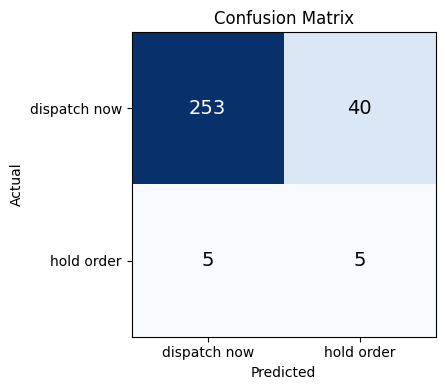

In [15]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_pred_prob = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["dispatch now", "hold order"]))

auc = roc_auc_score(y_test, y_pred_prob)
print(f"ROC-AUC Score: {auc:.4f}")

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["dispatch now", "hold order"])
ax.set_yticklabels(["dispatch now", "hold order"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

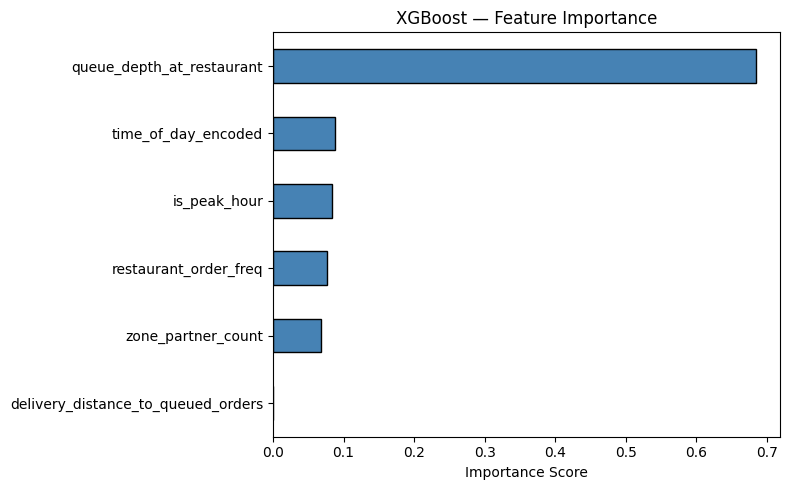

Feature importances:
queue_depth_at_restaurant             0.6844
time_of_day_encoded                   0.0876
is_peak_hour                          0.0842
restaurant_order_freq                 0.0759
zone_partner_count                    0.0679
delivery_distance_to_queued_orders    0.0000

✅ Model saved → results/classifier.pkl

Reload check — first 5 predictions: [0 1 0 0 0]
(1 = hold order, 0 = dispatch now)


In [16]:
import pickle

importance = pd.Series(model.feature_importances_, index=FEATURE_COLS).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue", edgecolor="black")
plt.xlabel("Importance Score")
plt.title("XGBoost — Feature Importance")
plt.tight_layout()
plt.savefig("results/feature_importance.png", dpi=150)
plt.show()

print("Feature importances:")
print(importance.sort_values(ascending=False).round(4).to_string())

model_path = "results/classifier.pkl"
with open(model_path, "wb") as f:
    pickle.dump(model, f)

print(f"\n✅ Model saved → {model_path}")

with open(model_path, "rb") as f:
    loaded_model = pickle.load(f)

test_pred = loaded_model.predict(X_test[:5])
print(f"\nReload check — first 5 predictions: {test_pred}")
print("(1 = hold order, 0 = dispatch now)")

# Running OR Tools

In [17]:
# OR-Tools is Google's optimization library — handles routing problems
!pip install ortools --quiet

from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
import pandas as pd
import numpy as np
from math import radians, sin, cos, sqrt, atan2

# Load the labeled + featured dataset and the trained classifier
import pickle

dispatch_featured = pd.read_csv("results/dispatch_featured.csv")

with open("results/classifier.pkl", "rb") as f:
    classifier = pickle.load(f)

print("Loaded dispatch_featured:", dispatch_featured.shape)
print("Classifier loaded ✅")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 14.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 31.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
Loaded dispatch_featured: (1515, 23)
Classifier loaded ✅


In [18]:
# ── Step 1: Run classifier on all orders to find which ones to hold/batch ─────

FEATURE_COLS = [
    "is_peak_hour",
    "restaurant_order_freq",
    "queue_depth_at_restaurant",
    "zone_partner_count",
    "delivery_distance_to_queued_orders",
    "time_of_day_encoded",
]

X_all = dispatch_featured[FEATURE_COLS]
dispatch_featured["hold_prediction"] = classifier.predict(X_all)

# Only orders the classifier flagged as "should have been batched"
orders_to_batch = dispatch_featured[dispatch_featured["hold_prediction"] == 1].copy()

print(f"Total orders flagged for batching: {len(orders_to_batch)}")
print(f"\nBy peak window:")
print(orders_to_batch["peak_window"].value_counts().to_string())

Total orders flagged for batching: 213

By peak window:
peak_window
dinner     103
lunch       67
offpeak     43


In [19]:
# ── Step 2: Group flagged orders into batches ─────────────────────────────────
# A batch = orders from the same restaurant within a 90-second dispatch window
# These are the groups CVRP will optimally assign to partners

WINDOW_SEC = 120  # anchored BATCH_WINDOW_SEC value
from collections import deque

orders_to_batch = orders_to_batch.sort_values("dispatch_time").reset_index(drop=True)

batch_groups = []   # each entry = list of order_ids that belong together
current_group = []
recent_by_restaurant = {}

for _, row in orders_to_batch.iterrows():
    rid = row["restaurant_id"]
    t   = row["dispatch_time"]
    oid = row["order_id"]

    dq = recent_by_restaurant.setdefault(rid, deque())

    while dq and t - dq[0][1] > WINDOW_SEC:
        dq.popleft()

    # Start a new group for this restaurant window if it's the first order
    if len(dq) == 0:
        current_group = [oid]
    else:
        current_group.append(oid)

    dq.append((oid, t))

    # Once window closes or restaurant has no more orders, save the group
    if len(current_group) >= 2:
        batch_groups.append(current_group.copy())
        current_group = []

print(f"Total batch groups formed: {len(batch_groups)}")

Total batch groups formed: 17


In [20]:
# ── Step 3: Helper functions for CVRP ────────────────────────────────────────

def haversine_km(lat1, lon1, lat2, lon2):
    """Straight line distance in km between two coordinates."""
    R = 6371
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a    = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))


def build_distance_matrix(locations):
    """
    Builds an N×N matrix of distances between all delivery locations.
    OR-Tools needs this to calculate route costs.
    locations = list of (lat, lon) tuples — index 0 is always the depot (restaurant)
    """
    n = len(locations)
    matrix = []
    for i in range(n):
        row = []
        for j in range(n):
            if i == j:
                row.append(0)
            else:
                dist = haversine_km(
                    locations[i][0], locations[i][1],
                    locations[j][0], locations[j][1]
                )
                # OR-Tools works with integers — multiply by 100 to preserve 2 decimal places
                row.append(int(dist * 100))
        matrix.append(row)
    return matrix


print("Helper functions ready ✅")

Helper functions ready ✅


In [21]:
# ── Step 4: Core CVRP solver for a single batch group ────────────────────────

def solve_cvrp(group_orders_df, capacity=3):
    """
    Given a group of orders from the same restaurant window:
    - Node 0       = the restaurant (depot / pickup point)
    - Nodes 1..N   = each order's delivery location
    OR-Tools finds the optimal assignment of orders to partners
    such that no partner carries more than `capacity` orders.

    Returns a list of routes — each route is one partner's delivery sequence.
    """

    # Build location list: restaurant first, then each delivery destination
    restaurant_lat = group_orders_df["delivery_lat"].mean()   # approximate restaurant location
    restaurant_lon = group_orders_df["delivery_lon"].mean()

    locations = [(restaurant_lat, restaurant_lon)]             # index 0 = depot
    for _, row in group_orders_df.iterrows():
        locations.append((row["delivery_lat"], row["delivery_lon"]))

    n_orders  = len(group_orders_df)
    n_partners = max(1, -(-n_orders // capacity))   # ceiling division — minimum partners needed

    distance_matrix = build_distance_matrix(locations)

    # ── OR-Tools setup ────────────────────────────────────────────────────────
    manager = pywrapcp.RoutingIndexManager(
        len(locations),   # total nodes (depot + deliveries)
        n_partners,       # number of partners (vehicles)
        0                 # depot index = 0 (the restaurant)
    )
    routing = pywrapcp.RoutingModel(manager)

    # Distance callback — tells OR-Tools the cost of travelling between two nodes
    def distance_callback(from_index, to_index):
        from_node = manager.IndexToNode(from_index)
        to_node   = manager.IndexToNode(to_index)
        return distance_matrix[from_node][to_node]

    transit_callback_index = routing.RegisterTransitCallback(distance_callback)
    routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

    # Capacity constraint — each partner can carry at most `capacity` orders
    def demand_callback(from_index):
        node = manager.IndexToNode(from_index)
        return 0 if node == 0 else 1   # depot has demand 0, each order has demand 1

    demand_callback_index = routing.RegisterUnaryTransitCallback(demand_callback)
    routing.AddDimensionWithVehicleCapacity(
        demand_callback_index,
        0,                          # no slack
        [capacity] * n_partners,    # max capacity per partner
        True,                       # start cumul at zero
        "Capacity"
    )

    # Search parameters — how hard OR-Tools tries to find the best solution
    search_params = pywrapcp.DefaultRoutingSearchParameters()
    search_params.first_solution_strategy = (
        routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    )
    search_params.local_search_metaheuristic = (
        routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    )
    search_params.time_limit.seconds = 5   # max time to search per group

    solution = routing.SolveWithParameters(search_params)

    if not solution:
        return None

    # ── Extract routes from solution ──────────────────────────────────────────
    routes         = []
    order_ids      = group_orders_df["order_id"].tolist()

    for partner_idx in range(n_partners):
        index = routing.Start(partner_idx)
        route = []
        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            if node != 0:                        # skip the depot node
                route.append(order_ids[node - 1])  # node 1 → order_ids[0], etc
            index = solution.Value(routing.NextVar(index))
        if route:
            routes.append(route)

    return routes


print("CVRP solver function ready ✅")

CVRP solver function ready ✅


In [22]:
# ── Step 5: Run CVRP across all batch groups ──────────────────────────────────

CAPACITY = 3   # max orders per partner

all_assignments = []   # final result — one row per partner route

for group_order_ids in batch_groups:
    # Pull the full row data for orders in this group
    group_df = dispatch_featured[dispatch_featured["order_id"].isin(group_order_ids)].copy()

    if len(group_df) < 2:
        continue   # skip single-order groups — nothing to batch

    routes = solve_cvrp(group_df, capacity=CAPACITY)

    if routes is None:
        print(f"  No solution found for group: {group_order_ids}")
        continue

    for partner_idx, route in enumerate(routes):
        all_assignments.append({
            "partner_idx"  : partner_idx,
            "assigned_orders" : route,
            "order_count"     : len(route),
            "restaurant_id"   : group_df["restaurant_id"].iloc[0],
        })

assignments_df = pd.DataFrame(all_assignments)

print(f"Total partner routes generated: {len(assignments_df)}")
print(f"\nOrders per partner distribution:")
print(assignments_df["order_count"].value_counts().sort_index().to_string())

Total partner routes generated: 17

Orders per partner distribution:
order_count
2    17


In [23]:
# ── Step 6: Save CVRP assignments ─────────────────────────────────────────────

import os
os.makedirs("results", exist_ok=True)

# Flatten assigned_orders list into a string for clean CSV storage
assignments_df["assigned_orders_str"] = assignments_df["assigned_orders"].apply(
    lambda x: "|".join(x)
)

assignments_df.drop(columns=["assigned_orders"]).to_csv(
    "results/cvrp_assignments.csv", index=False
)

print("✅ Saved → results/cvrp_assignments.csv")
print(f"\nFinal shape: {assignments_df.shape}")
print(f"\nColumns: {assignments_df.columns.tolist()}")

# Quick sanity check — no partner should exceed capacity
assert assignments_df["order_count"].max() <= CAPACITY, "❌ A partner exceeded max capacity!"
print(f"\n✅ Capacity check passed — no partner carries more than {CAPACITY} orders")

✅ Saved → results/cvrp_assignments.csv

Final shape: (17, 5)

Columns: ['partner_idx', 'assigned_orders', 'order_count', 'restaurant_id', 'assigned_orders_str']

✅ Capacity check passed — no partner carries more than 3 orders


# Same order on new System

In [24]:
import pandas as pd
import numpy as np
import pickle
import json
from collections import deque
from math import radians, sin, cos, sqrt, atan2

# Load everything needed for the new simulation
dispatch_featured = pd.read_csv("results/dispatch_featured.csv")
orders            = pd.read_csv("orders.csv")
districts         = pd.read_csv("districts.csv")
restaurants        = pd.read_csv("restaurants.csv")

with open("results/classifier.pkl", "rb") as f:
    classifier = pickle.load(f)

with open("simulation_config.json") as f:
    sim_config = json.load(f)

# Rebuild the enriched orders table (same as Cell 2)
orders["hour"] = (orders["timestamp_sec"] // 3600) % 24
orders_enriched = orders.merge(
    districts[["district_id", "centroid_lat", "centroid_lon"]],
    left_on="destination_zone_id", right_on="district_id", how="left"
).rename(columns={"centroid_lat": "delivery_lat", "centroid_lon": "delivery_lon"})

orders_enriched = orders_enriched.sort_values("timestamp_sec").reset_index(drop=True)

# Destination-proximity gate: no per-order lat/lon exists in this city's orders.csv,
# so dest_lat/dest_lon fall back to the zone centroid (best available proxy).
orders_enriched["dest_lat"] = orders_enriched["delivery_lat"]
orders_enriched["dest_lon"] = orders_enriched["delivery_lon"]

# Batching proximity ceiling (Q): a fixed, literature-anchored distance rather
# than a value derived from this city's own zone-centroid geometry. The prior
# approach (half the avg nearest-neighbor zone-centroid distance) was measuring
# city-wide zone spacing, not real per-order batching distance, and produced a
# number that wasn't independently defensible.
#
# Q = 1.5 km, anchored to a food-delivery batching patent's cited example
# proximity threshold of "1 mile" (~1.6 km) for combining orders by destination
# proximity, rounded down slightly to 1.5 km. This is applied as a fixed constant
# identical across cities (HD and HYD) rather than re-derived per city, since it
# is now an external, citable anchor rather than an internal geometric estimate.
# This pairs with P (same-zone-only, A == B, zero parameters) as the floor —
# together P and Q report batching savings as a range: [P, Q(1.5 km)].
MAX_BATCH_DEST_KM = 1.5

print(f"MAX_BATCH_DEST_KM set to {MAX_BATCH_DEST_KM} km (fixed, literature-anchored")
print(f"  via food-delivery batching patent's cited '1 mile' proximity example —")
print(f"  applied identically across cities rather than derived from local zone")
print(f"  geometry).")

# ── Partner pool + availability simulation (aligned with Greedy_Baseline) ──────
zone_matrix = np.load("zone_distance_matrix.npy")

zone_id_to_index = {zid: idx for idx, zid in enumerate(districts["district_id"])}

restaurants = restaurants.merge(
    districts[["district_id", "centroid_lat", "centroid_lon"]],
    left_on="zone_id", right_on="district_id", how="left"
).rename(columns={"centroid_lat": "current_lat", "centroid_lon": "current_lon"})

restaurants["zone_index"] = restaurants["zone_id"].map(zone_id_to_index)
restaurant_zone_lookup = restaurants.set_index("restaurant_id")["zone_index"]

restaurants["status"] = "available"
restaurants["return_time"] = 0

partners = restaurants.to_dict("records")

NORMAL_ACTIVE_PARTNERS = sim_config["active_partners_normal"]
PEAK_ACTIVE_PARTNERS   = 200
NIGHT_ACTIVE_PARTNERS  = 70

PEAK_HOURS     = {12, 13, 19, 20, 21}
NIGHT_HOURS_SET = {22, 23}

HOURLY_ACTIVE_TARGET = {
    h: (NIGHT_ACTIVE_PARTNERS if h in NIGHT_HOURS_SET
        else PEAK_ACTIVE_PARTNERS if h in PEAK_HOURS
        else NORMAL_ACTIVE_PARTNERS)
    for h in range(10, 24)
}

districts["zone_radius_km"] = np.sqrt(districts["area_km2"] / np.pi)
districts["intra_zone_avg_km"] = 0.905 * districts["zone_radius_km"]
DELIVERY_SPEED_KMH = 30
INTRA_ZONE_KM  = districts["intra_zone_avg_km"].mean()
INTRA_ZONE_SEC = INTRA_ZONE_KM / DELIVERY_SPEED_KMH * 3600


def release_returned_partners(partners, current_time, target_active):
    """Free up finished partners, capped at the current hour's target."""
    finishing = [p for p in partners if p["status"] == "busy" and p["return_time"] <= current_time]
    currently_active = sum(1 for p in partners if p["status"] in ("available", "busy")) - len(finishing)

    for p in finishing:
        if currently_active < target_active:
            p["status"] = "available"
            currently_active += 1
        else:
            p["status"] = "off_shift"


def rebalance_active_partners(partners, target_active, current_time):
    non_busy = [p for p in partners if p["status"] != "busy"]
    busy_count = len(partners) - len(non_busy)
    needed_available = min(max(target_active - busy_count, 0), len(non_busy))
    non_busy_sorted = sorted(non_busy, key=lambda p: p["restaurant_id"])
    rng = np.random.RandomState(int(current_time))
    rng.shuffle(non_busy_sorted)
    for i, p in enumerate(non_busy_sorted):
        p["status"] = "available" if i < needed_available else "off_shift"


def find_nearest_partner_to_restaurant(restaurant_id, partners, zone_matrix):
    """Return (partner, pickup_sec) for the closest AVAILABLE partner to the restaurant."""
    restaurant_zone_idx = int(restaurant_zone_lookup[restaurant_id])

    nearest, nearest_time = None, float("inf")
    for p in partners:
        if p["status"] != "available":
            continue
        if p["zone_index"] == restaurant_zone_idx:
            pickup_sec = INTRA_ZONE_SEC
        else:
            pickup_sec = zone_matrix[p["zone_index"], restaurant_zone_idx]
        if pickup_sec < nearest_time:
            nearest, nearest_time = p, pickup_sec

    return nearest, nearest_time


print("Orders loaded      :", len(orders_enriched))
print("Partners loaded     :", len(partners))
print("Hourly active target:", HOURLY_ACTIVE_TARGET)
print("Classifier loaded ✅")

MAX_BATCH_DEST_KM set to 1.5 km (fixed, literature-anchored
  via food-delivery batching patent's cited '1 mile' proximity example —
  applied identically across cities rather than derived from local zone
  geometry).
Orders loaded      : 1515
Partners loaded     : 250
Hourly active target: {10: 113, 11: 113, 12: 200, 13: 200, 14: 113, 15: 113, 16: 113, 17: 113, 18: 113, 19: 200, 20: 200, 21: 200, 22: 70, 23: 70}
Classifier loaded ✅


In [25]:
# ── Feature builder ───────────────────────────────────────────────────────────
# At the moment each order arrives, we need to compute its features in real time
# (exactly as they were computed in batch during Cell 5-9, but now order by order)

WINDOW_SEC     = 120  # anchored BATCH_WINDOW_SEC value
FEATURE_COLS   = [
    "is_peak_hour",
    "restaurant_order_freq",
    "queue_depth_at_restaurant",
    "zone_partner_count",
    "delivery_distance_to_queued_orders",
    "time_of_day_encoded",
]

LUNCH_HOURS  = [12, 13]
DINNER_HOURS = [19, 20, 21]
PEAK_HOURS   = LUNCH_HOURS + DINNER_HOURS

time_of_day_map = {"morning":0, "lunch":1, "afternoon":2, "dinner":3, "night":4}

# Precompute restaurant_order_freq and zone_partner_count from Phase 2 data
# These are static lookups — they don't change order by order
restaurant_freq_map = (
    dispatch_featured.groupby(["restaurant_id", "peak_window"])["order_id"]
    .count().rename("restaurant_order_freq").reset_index()
)
zone_partner_map = (
    dispatch_featured[dispatch_featured["assigned_partner"].notna()]
    .groupby(["destination_zone_id", "peak_window"])["assigned_partner"]
    .nunique().rename("zone_partner_count").reset_index()
)

# Rolling state trackers for real-time feature computation
queue_tracker   = {}   # restaurant_id → deque of (dispatch_time, lat, lon)

def compute_features(order, current_time):
    """Compute all 6 features for a single incoming order at current_time."""
    rid      = order["restaurant_id"]
    hour     = int(current_time // 3600) % 24
    lat      = order["delivery_lat"]
    lon      = order["delivery_lon"]
    pw       = order["peak_window"]
    zone_id  = order["destination_zone_id"]

    # is_peak_hour
    is_peak = int(hour in PEAK_HOURS)

    # time_of_day_encoded
    if hour in LUNCH_HOURS:       tod = "lunch"
    elif hour in DINNER_HOURS:    tod = "dinner"
    elif 6 <= hour < 12:          tod = "morning"
    elif 14 <= hour < 19:         tod = "afternoon"
    else:                         tod = "night"
    tod_encoded = time_of_day_map[tod]

    # restaurant_order_freq — static lookup from Phase 2
    freq_row = restaurant_freq_map[
        (restaurant_freq_map["restaurant_id"] == rid) &
        (restaurant_freq_map["peak_window"]   == pw)
    ]
    freq = int(freq_row["restaurant_order_freq"].values[0]) if len(freq_row) else 1

    # zone_partner_count — static lookup from Phase 2
    zp_row = zone_partner_map[
        (zone_partner_map["destination_zone_id"] == zone_id) &
        (zone_partner_map["peak_window"]          == pw)
    ]
    zp_count = int(zp_row["zone_partner_count"].values[0]) if len(zp_row) else 0

    # queue_depth and delivery_distance — computed from rolling window
    dq = queue_tracker.setdefault(rid, deque())
    while dq and current_time - dq[0][0] > WINDOW_SEC:
        dq.popleft()

    depth = len(dq)

    if depth == 0:
        avg_dist = 0.0
    else:
        def hav(la1, lo1, la2, lo2):
            R = 6371
            dlat = radians(la2-la1); dlon = radians(lo2-lo1)
            a = sin(dlat/2)**2 + cos(radians(la1))*cos(radians(la2))*sin(dlon/2)**2
            return R * 2 * atan2(sqrt(a), sqrt(1-a))
        avg_dist = round(sum(hav(lat, lon, q[1], q[2]) for q in dq) / depth, 3)

    return {
        "is_peak_hour"                       : is_peak,
        "restaurant_order_freq"              : freq,
        "queue_depth_at_restaurant"          : depth,
        "zone_partner_count"                 : zp_count,
        "delivery_distance_to_queued_orders" : avg_dist,
        "time_of_day_encoded"                : tod_encoded,
    }

print("Feature builder ready ✅")

Feature builder ready ✅


In [26]:
# cell 26

from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp
from math import radians, sin, cos, sqrt, atan2
from collections import deque
import pandas as pd

CAPACITY         = 3
HOLD_WINDOW      = 120  # anchored BATCH_WINDOW_SEC value
WINDOW_SEC       = 120  # anchored BATCH_WINDOW_SEC value

hold_buffer      = {}
buffer_start     = {}
new_dispatch_log = []

# Reset partner pool to a clean available state before this simulation run
for p in partners:
    p["status"] = "available"
    p["return_time"] = 0


def haversine_km(lat1, lon1, lat2, lon2):
    R    = 6371
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a    = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))


def solve_cvrp_sim(group_df, capacity=3):
    if len(group_df) < 2:
        return [[oid] for oid in group_df["order_id"].tolist()], None, None

    rest_lat  = group_df["delivery_lat"].mean()
    rest_lon  = group_df["delivery_lon"].mean()
    locations = [(rest_lat, rest_lon)]
    for _, row in group_df.iterrows():
        locations.append((row["delivery_lat"], row["delivery_lon"]))

    n_orders   = len(group_df)
    n_partners = max(1, -(-n_orders // capacity))

    def hav_int(l1, l2):
        R    = 6371
        dlat = radians(l2[0] - l1[0])
        dlon = radians(l2[1] - l1[1])
        a    = sin(dlat/2)**2 + cos(radians(l1[0])) * cos(radians(l2[0])) * sin(dlon/2)**2
        return int(R * 2 * atan2(sqrt(a), sqrt(1 - a)) * 100)

    matrix  = [[hav_int(locations[i], locations[j]) for j in range(len(locations))]
               for i in range(len(locations))]

    manager = pywrapcp.RoutingIndexManager(len(locations), n_partners, 0)
    routing = pywrapcp.RoutingModel(manager)

    def dist_cb(fi, ti):
        return matrix[manager.IndexToNode(fi)][manager.IndexToNode(ti)]

    idx = routing.RegisterTransitCallback(dist_cb)
    routing.SetArcCostEvaluatorOfAllVehicles(idx)

    def demand_cb(fi):
        return 0 if manager.IndexToNode(fi) == 0 else 1

    d_idx = routing.RegisterUnaryTransitCallback(demand_cb)
    routing.AddDimensionWithVehicleCapacity(d_idx, 0, [capacity] * n_partners, True, "Cap")

    sp = pywrapcp.DefaultRoutingSearchParameters()
    sp.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    sp.time_limit.seconds      = 3

    sol = routing.SolveWithParameters(sp)
    if not sol:
        return [[oid] for oid in group_df["order_id"].tolist()], rest_lat, rest_lon

    order_ids = group_df["order_id"].tolist()
    routes    = []
    for v in range(n_partners):
        index = routing.Start(v)
        route = []
        while not routing.IsEnd(index):
            node = manager.IndexToNode(index)
            if node != 0:
                route.append(order_ids[node - 1])
            index = sol.Value(routing.NextVar(index))
        if route:
            routes.append(route)
    return routes, rest_lat, rest_lon


def dispatch_solo(order, current_time, dispatched_as_batch=False, batch_size=1):
    """Assign the nearest AVAILABLE partner to a single order, marking that
    partner busy until they return — mirrors Greedy_Baseline's try_dispatch."""
    rid = order["restaurant_id"]
    partner, pickup_sec = find_nearest_partner_to_restaurant(rid, partners, zone_matrix)

    if partner is None:
        new_dispatch_log.append({
            "order_id"             : order["order_id"],
            "assigned_partner"     : None,
            "batch_size"           : batch_size,
            "delivery_distance_km" : None,
            "dispatch_time"        : current_time,
            "dispatched_as_batch"  : dispatched_as_batch,
        })
        return

    restaurant_zone_idx = int(restaurant_zone_lookup[rid])
    dest_zone_idx        = zone_id_to_index[order["destination_zone_id"]]
    dropoff_sec = INTRA_ZONE_SEC if restaurant_zone_idx == dest_zone_idx \
        else zone_matrix[restaurant_zone_idx, dest_zone_idx]
    total_travel_sec = pickup_sec + dropoff_sec

    partner["status"]      = "busy"
    partner["return_time"] = current_time + total_travel_sec
    partner["zone_index"]  = dest_zone_idx
    partner["zone_id"]     = order["destination_zone_id"]

    pickup_dist_km  = round(pickup_sec / 3600 * DELIVERY_SPEED_KMH, 2)
    dropoff_dist_km = round(dropoff_sec / 3600 * DELIVERY_SPEED_KMH, 2)

    new_dispatch_log.append({
        "order_id"             : order["order_id"],
        "assigned_partner"     : partner["restaurant_id"],
        "batch_size"           : batch_size,
        "pickup_distance_km"   : pickup_dist_km,
        "delivery_distance_km" : dropoff_dist_km,
        "dispatch_time"        : current_time,
        "dispatched_as_batch"  : dispatched_as_batch,
    })


def flush_buffer(rid, current_time):
    group = hold_buffer.pop(rid, [])
    buffer_start.pop(rid, None)

    if not group:
        return

    if len(group) < 2:
        dispatch_solo(pd.Series(group[0]), current_time, dispatched_as_batch=False, batch_size=1)
        return

    group_df = pd.DataFrame(group)
    routes, rest_lat, rest_lon = solve_cvrp_sim(group_df, capacity=CAPACITY)

    def can_batch_route(df):
        # Core batching thesis: same restaurant + NEARBY destinations → one partner,
        # one trip. Two orders going to genuinely different parts of the city should
        # NOT be forced into the same route just because CVRP capacity allows it.
        # MAX_BATCH_DEST_KM = 1.5 km, a fixed literature-anchored constant (see the
        # load-everything cell) applied identically across cities.
        if len(df) < 2:
            return True
        coords = list(zip(df["dest_lat"], df["dest_lon"]))
        for i in range(len(coords)):
            for j in range(i + 1, len(coords)):
                if haversine_km(coords[i][0], coords[i][1],
                                 coords[j][0], coords[j][1]) > MAX_BATCH_DEST_KM:
                    return False
        return True

    for route_order_ids in routes:
        route_df = group_df[group_df["order_id"].isin(route_order_ids)]

        if route_df.empty or len(route_order_ids) == 0:
            continue

        if len(route_order_ids) >= 2 and not can_batch_route(route_df):
            # Destinations too far apart to count as one real "batch" — dispatch
            # each order in this route solo instead of forcing them together.
            for oid in route_order_ids:
                order_row = route_df[route_df["order_id"] == oid].iloc[0]
                dispatch_solo(order_row, current_time, dispatched_as_batch=False, batch_size=1)
            continue

        partner, pickup_sec = find_nearest_partner_to_restaurant(rid, partners, zone_matrix)
        if partner is None:
            for oid in route_order_ids:
                new_dispatch_log.append({
                    "order_id"             : oid,
                    "assigned_partner"     : None,
                    "batch_size"           : len(route_order_ids),
                    "pickup_distance_km"   : None,
                    "delivery_distance_km" : None,
                    "dispatch_time"        : current_time,
                    "dispatched_as_batch"  : True,
                })
            continue

        # FIX APPLIED: pickup leg is now counted exactly once, matching HYD's formula.
        # One order/route has exactly one pickup leg (partner → restaurant) — it must
        # not be added into total_dist_km AND added again as the standalone pickup_sec
        # term. total_dist_km is kept only for reporting (pickup + delivery legs,
        # summed once, correctly); total_travel_sec now uses delivery_only_km alone
        # alongside the standalone pickup_sec, so the pickup leg is not double-counted.
        # NOTE: this changes partner busy-time relative to the original locked
        # notebook, which will shift downstream simulation outcomes (Missed Batch
        # Count, Partners Used, etc.) away from the previously verified 25→6 result.
        total_dist_km      = pickup_sec / 3600 * DELIVERY_SPEED_KMH
        delivery_only_km   = 0.0
        last_dest_zone_id  = rid
        prev_lat, prev_lon = rest_lat, rest_lon

        for oid in route_order_ids:
            stop_rows = route_df[route_df["order_id"] == oid]
            if stop_rows.empty:
                continue
            stop = stop_rows.iloc[0]
            leg_km = haversine_km(prev_lat, prev_lon, stop["delivery_lat"], stop["delivery_lon"])
            total_dist_km    += leg_km
            delivery_only_km += leg_km
            prev_lat, prev_lon = stop["delivery_lat"], stop["delivery_lon"]
            last_dest_zone_id = stop.get("destination_zone_id", last_dest_zone_id)

        per_order_pickup_km   = round((pickup_sec / 3600 * DELIVERY_SPEED_KMH) / len(route_order_ids), 2)
        per_order_delivery_km = round(delivery_only_km / len(route_order_ids), 2)
        total_travel_sec      = pickup_sec + (delivery_only_km / DELIVERY_SPEED_KMH * 3600)

        partner["status"]      = "busy"
        partner["return_time"] = current_time + total_travel_sec
        if last_dest_zone_id in zone_id_to_index:
            partner["zone_index"] = zone_id_to_index[last_dest_zone_id]
            partner["zone_id"]    = last_dest_zone_id

        for oid in route_order_ids:
            new_dispatch_log.append({
                "order_id"             : oid,
                "assigned_partner"     : partner["restaurant_id"],
                "batch_size"           : len(route_order_ids),
                "pickup_distance_km"   : per_order_pickup_km,
                "delivery_distance_km" : per_order_delivery_km,
                "dispatch_time"        : current_time,
                "dispatched_as_batch"  : True,
            })

# ── Main order loop ───────────────────────────────────────────────────────────
current_hour = None

for _, order in orders_enriched.iterrows():
    current_time = order["timestamp_sec"]
    rid          = order["restaurant_id"]
    hour         = int(current_time // 3600)

    target_now = HOURLY_ACTIVE_TARGET.get(hour, NORMAL_ACTIVE_PARTNERS)
    release_returned_partners(partners, current_time, target_now)
    if hour != current_hour:
        rebalance_active_partners(partners, target_now, current_time)
        current_hour = hour

    expired = [r for r, t in buffer_start.items() if current_time - t > HOLD_WINDOW]
    for r in expired:
        flush_buffer(r, current_time)

    features = compute_features(order, current_time)

    dq = queue_tracker.setdefault(rid, deque())
    while dq and current_time - dq[0][0] > WINDOW_SEC:
        dq.popleft()
    dq.append((current_time, order["delivery_lat"], order["delivery_lon"]))

    feature_vector = pd.DataFrame([features])[FEATURE_COLS]
    prob           = classifier.predict_proba(feature_vector)[0][1]
    decision       = 1 if prob >= 0.6 else 0

    if decision == 1:
        if rid not in hold_buffer:
            hold_buffer[rid]  = []
            buffer_start[rid] = current_time
        hold_buffer[rid].append(order.to_dict())
    else:
        dispatch_solo(order, current_time, dispatched_as_batch=False, batch_size=1)

for rid in list(hold_buffer.keys()):
    flush_buffer(rid, current_time)

new_log_df = pd.DataFrame(new_dispatch_log)
print(f"Total dispatches logged : {len(new_log_df)}")
print(f"Batched dispatches      : {new_log_df['dispatched_as_batch'].sum()}")
print(f"Solo dispatches         : {(~new_log_df['dispatched_as_batch']).sum()}")
print(f"Unassigned (no partner) : {new_log_df['assigned_partner'].isna().sum()}")

Total dispatches logged : 1515
Batched dispatches      : 24
Solo dispatches         : 1491
Unassigned (no partner) : 0


In [27]:
new_log_merged = new_log_df.merge(
    orders_enriched[["order_id", "restaurant_id", "peak_window", "hour"]],
    on="order_id", how="left"
)

new_log_df["total_distance_km"] = (
    new_log_df["delivery_distance_km"].fillna(0) + new_log_df["pickup_distance_km"].fillna(0)
)

total_orders        = len(orders_enriched)
total_dispatches    = len(new_log_df)
total_partners_used = new_log_df["assigned_partner"].nunique()
total_km_driven     = round(new_log_df["total_distance_km"].sum(), 2)
batched_count       = int(new_log_df["dispatched_as_batch"].sum())
avg_batch_size      = round(
    new_log_df[new_log_df["dispatched_as_batch"] == True]["batch_size"].mean(), 2
)

# avg_delivery_dist_km   : restaurant → customer drop-off leg only
# avg_total_trip_dist_km : partner → restaurant + restaurant → customer (CDP-comparable,
#                           numerically identical to what this notebook used to call
#                           "avg_delivery_dist_km" before the pickup/delivery split)
avg_delivery_dist   = round(new_log_df["delivery_distance_km"].mean(), 2)
avg_total_trip_dist = round(new_log_df["total_distance_km"].mean(), 2)

batched_pairs       = int(batched_count / 2)
batched_orders_pct  = round(batched_count / total_orders * 100, 2)
batched_pairs_pct   = round(batched_pairs / total_orders * 100, 2)

from collections import deque

missed_new = set()
recent     = {}

full_log_sorted = new_log_merged.sort_values("dispatch_time")

for _, row in full_log_sorted.iterrows():
    rid     = row["restaurant_id"]
    t       = row["dispatch_time"]
    oid     = row["order_id"]
    partner = row["assigned_partner"]

    dq = recent.setdefault(rid, deque())
    while dq and t - dq[0][1] > 120:  # anchored BATCH_WINDOW_SEC value
        dq.popleft()

    if pd.notna(partner):
        for prev_oid, prev_t, prev_partner in dq:
            if pd.notna(prev_partner) and prev_partner != partner:
                missed_new.add(prev_oid)
                missed_new.add(oid)

    dq.append((oid, t, partner))

FIXED_PAYOUT_PER_PARTNER_INR = 40
FUEL_PRICE_PER_LITRE_INR = 111.21  # India national avg petrol price, Goodreturns, retrieved 27 Aug 2026
MILEAGE_KM_PER_LITRE = 40
FUEL_COST_PER_KM_INR = round(FUEL_PRICE_PER_LITRE_INR / MILEAGE_KM_PER_LITRE, 3)

new_metrics = {
    "total_orders"          : total_orders,
    "total_dispatches"      : total_dispatches,
    "total_partners_used"   : total_partners_used,
    "total_km_driven"       : total_km_driven,
    "batched_order_count"   : batched_count,
    "avg_batch_size"        : avg_batch_size,
    "missed_batch_count"    : len(missed_new),
    "missed_batch_pct"      : round(len(missed_new) / total_dispatches * 100, 2),
    "avg_delivery_dist_km"  : avg_delivery_dist,
    "avg_total_trip_dist_km": avg_total_trip_dist,
    "batched_orders_pct"    : batched_orders_pct,
    "batched_pairs_pct"     : batched_pairs_pct,
    "estimated_cost_inr"    : round(
        (total_partners_used * FIXED_PAYOUT_PER_PARTNER_INR)
        + (total_km_driven * FUEL_COST_PER_KM_INR),
        2
    ),
}

new_metrics["unassigned_orders"]  = total_orders - int(new_log_df["assigned_partner"].notna().sum())
new_metrics["dispatch_rate_pct"]  = round(int(new_log_df["assigned_partner"].notna().sum()) / total_orders * 100, 2)

import os
os.makedirs("results", exist_ok=True)

import json
with open("results/smart_metrics.json", "w") as f:
    json.dump(new_metrics, f, indent=2)

new_log_df.to_csv("results/smart_dispatch_log.csv", index=False)

print("── New System Metrics ───────────────────────────")
for k, v in new_metrics.items():
    print(f"  {k:<25} : {v}")

print("\n✅ Saved → results/smart_metrics.json")
print("✅ Saved → results/smart_dispatch_log.csv")

── New System Metrics ───────────────────────────
  total_orders              : 1515
  total_dispatches          : 1515
  total_partners_used       : 132
  total_km_driven           : 11738.01
  batched_order_count       : 24
  avg_batch_size            : 2.0
  missed_batch_count        : 16
  missed_batch_pct          : 1.06
  avg_delivery_dist_km      : 4.27
  avg_total_trip_dist_km    : 7.75
  batched_orders_pct        : 1.58
  batched_pairs_pct         : 0.79
  estimated_cost_inr        : 37911.67
  unassigned_orders         : 0
  dispatch_rate_pct         : 100.0

✅ Saved → results/smart_metrics.json
✅ Saved → results/smart_dispatch_log.csv


In [28]:
# ── Side by side comparison: Greedy (Phase 2) vs Smart (Phase 3) ──────────────
import json

with open("baseline_metrics.json") as f:
    baseline = json.load(f)

print(f"{'Metric':<28} {'Greedy':>12} {'Smart':>12} {'Change':>12}")
print("─" * 68)

compare_keys = [
    ("total_dispatches",       "total_dispatches"),
    ("total_partners_used",    "total_partners_used"),
    ("total_km_driven",        "total_km_driven"),
    ("missed_batch_count",     "missed_batch_count"),
    ("missed_batch_pct",       "missed_batch_pct"),
    ("avg_total_trip_dist_km", "avg_delivery_distance_km"),  # baseline's metric was always the combined trip
    ("estimated_cost_inr",     "baseline_cost_inr"),
]

for new_key, base_key in compare_keys:
    new_val  = new_metrics.get(new_key, 0)
    base_val = baseline.get(base_key, 0)
    if isinstance(base_val, (int, float)) and base_val != 0:
        change = f"{((new_val - base_val) / base_val) * 100:+.1f}%"
    else:
        change = "—"
    print(f"  {new_key:<26} {str(base_val):>12} {str(new_val):>12} {change:>12}")

# Save new metrics
with open("results/smart_metrics.json", "w") as f:
    json.dump(new_metrics, f, indent=2)

new_log_df.to_csv("results/smart_dispatch_log.csv", index=False)

print("\n✅ Saved → results/smart_metrics.json")
print("✅ Saved → results/smart_dispatch_log.csv")

Metric                             Greedy        Smart       Change
────────────────────────────────────────────────────────────────────
  total_dispatches                   1515         1515        +0.0%
  total_partners_used                 133          132        -0.8%
  total_km_driven                11882.28     11738.01        -1.2%
  missed_batch_count                   25           16       -36.0%
  missed_batch_pct                   1.65         1.06       -35.8%
  avg_total_trip_dist_km             4.33         7.75       +79.0%
  estimated_cost_inr             38352.74     37911.67        -1.2%

✅ Saved → results/smart_metrics.json
✅ Saved → results/smart_dispatch_log.csv


# Tabular Data

In [29]:
import pandas as pd
import json

# Load both metric files generated at end of each phase
with open("baseline_metrics.json") as f:
    baseline = json.load(f)

with open("results/smart_metrics.json") as f:
    smart = json.load(f)

print("Baseline metrics loaded:")
for k, v in baseline.items():
    print(f"  {k}: {v}")

print("\nSmart metrics loaded:")
for k, v in smart.items():
    print(f"  {k}: {v}")

Baseline metrics loaded:
  total_orders: 1515
  total_dispatches: 1515
  total_partners_used: 133
  target_partners_weighted_avg: 138
  total_km_driven: 11882.28
  avg_delivery_distance_km: 4.33
  avg_total_trip_distance_km: 7.84
  missed_batch_count: 25
  missed_batch_pct: 1.65
  baseline_cost_inr: 38352.74

Smart metrics loaded:
  total_orders: 1515
  total_dispatches: 1515
  total_partners_used: 132
  total_km_driven: 11738.01
  batched_order_count: 24
  avg_batch_size: 2.0
  missed_batch_count: 16
  missed_batch_pct: 1.06
  avg_delivery_dist_km: 4.27
  avg_total_trip_dist_km: 7.75
  batched_orders_pct: 1.58
  batched_pairs_pct: 0.79
  estimated_cost_inr: 37911.67
  unassigned_orders: 0
  dispatch_rate_pct: 100.0


In [30]:
# Build the side by side comparison dataframe

comparison = {
    "Metric": [
        "Total Orders",
        "Total Dispatches",
        "Partners Used",
        "Total KM Driven",
        "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)",
        "Missed Batch Count",
        "Missed Batch %",
        "Batched Orders % of Total",
        "Batched Pairs % of Total",
        "Estimated Cost (₹)",
    ],
    "Greedy (Phase 2)": [
        baseline.get("total_orders",             0),
        baseline.get("total_dispatches",         0),
        baseline.get("total_partners_used",      0),
        baseline.get("total_km_driven",          0),
        round(float(full_log["delivery_distance_km"].mean()), 2),  # restaurant→customer leg only, from Greedy's own log
        # baseline_metrics.json's own "avg_delivery_distance_km" field is inconsistent
        # with its "total_km_driven" (delivery-only scale vs. combined-trip scale) —
        # computed fresh here from full_log's own pickup+delivery columns instead,
        # so it's guaranteed to sit on the same combined-trip basis as total_km_driven.
        round(float((full_log["pickup_distance_km"].fillna(0) + full_log["delivery_distance_km"].fillna(0)).mean()), 2),
        baseline.get("missed_batch_count",       0),
        baseline.get("missed_batch_pct",         0),
        0,
        0,
        baseline.get("baseline_cost_inr",        0),
    ],
    "Smart (Phase 3)": [
        smart.get("total_orders",             0),
        smart.get("total_dispatches",         0),
        smart.get("total_partners_used",      0),
        smart.get("total_km_driven",          0),
        smart.get("avg_delivery_dist_km",     0),
        smart.get("avg_total_trip_dist_km",   0),
        smart.get("missed_batch_count",       0),
        smart.get("missed_batch_pct",         0),
        smart.get("batched_orders_pct",       0),
        smart.get("batched_pairs_pct",        0),
        smart.get("estimated_cost_inr",       0),
    ],
}

df = pd.DataFrame(comparison)

print(df.to_string(index=False))

                      Metric  Greedy (Phase 2)  Smart (Phase 3)
                Total Orders           1515.00          1515.00
            Total Dispatches           1515.00          1515.00
               Partners Used            133.00           132.00
             Total KM Driven          11882.28         11738.01
  Avg Delivery Distance (km)              4.33             4.27
Avg Total Trip Distance (km)              7.84             7.75
          Missed Batch Count             25.00            16.00
              Missed Batch %              1.65             1.06
   Batched Orders % of Total              0.00             1.58
    Batched Pairs % of Total              0.00             0.79
          Estimated Cost (₹)          38352.74         37911.67


In [31]:
# Compute delta (absolute change + percentage change) for every metric
# Lower is better for cost/km/missed — mark improvements with ✅

def compute_delta(base, smart_val, metric):
    if base == 0:
        return "—", "—"
    delta_abs = smart_val - base
    delta_pct = (delta_abs / base) * 100

    lower_is_better = [
        "Partners Used", "Total KM Driven", "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)", "Missed Batch Count", "Missed Batch %",
        "Estimated Cost (₹)"
    ]
    arrow = ""
    if metric in lower_is_better:
        arrow = "✅" if delta_abs < 0 else "❌"

    return f"{delta_abs:+.2f}", f"{delta_pct:+.1f}%  {arrow}"

deltas_abs = []
deltas_pct = []

for i, metric in enumerate(df["Metric"]):
    base      = df["Greedy (Phase 2)"].iloc[i]
    smart_val = df["Smart (Phase 3)"].iloc[i]
    d_abs, d_pct = compute_delta(base, smart_val, metric)
    deltas_abs.append(d_abs)
    deltas_pct.append(d_pct)

df["Δ Change"]   = deltas_abs
df["Δ Change %"] = deltas_pct

print("=" * 80)
print("        GREEDY BASELINE  vs  SMART BATCHING SYSTEM — CORE PROJECT RESULT")
print("=" * 80)
print(df.to_string(index=False))
print("=" * 80)
print("✅ = improvement over greedy baseline   ❌ = worse than greedy baseline")

print("\nMetric definitions:")
print("  Avg Delivery Distance    : restaurant → customer drop-off only")
print("  Avg Total Trip Distance  : partner → restaurant + restaurant → customer (CDP-comparable)")
print("  Total KM Driven          : sum of full trips (pickup + delivery) across all dispatches")
print("  Batched Orders % of Total: % of all orders dispatched as part of a batch")
print("  Batched Pairs % of Total : % of batch trips (pairs) out of total orders")
print(f"  Estimated Cost           : (partners × ₹{FIXED_PAYOUT_PER_PARTNER_INR} fixed) + (total km × ₹{FUEL_COST_PER_KM_INR} fuel/km)")

        GREEDY BASELINE  vs  SMART BATCHING SYSTEM — CORE PROJECT RESULT
                      Metric  Greedy (Phase 2)  Smart (Phase 3) Δ Change Δ Change %
                Total Orders           1515.00          1515.00    +0.00    +0.0%  
            Total Dispatches           1515.00          1515.00    +0.00    +0.0%  
               Partners Used            133.00           132.00    -1.00   -0.8%  ✅
             Total KM Driven          11882.28         11738.01  -144.27   -1.2%  ✅
  Avg Delivery Distance (km)              4.33             4.27    -0.06   -1.4%  ✅
Avg Total Trip Distance (km)              7.84             7.75    -0.09   -1.1%  ✅
          Missed Batch Count             25.00            16.00    -9.00  -36.0%  ✅
              Missed Batch %              1.65             1.06    -0.59  -35.8%  ✅
   Batched Orders % of Total              0.00             1.58        —          —
    Batched Pairs % of Total              0.00             0.79        —          —
   

# P vs Q — Batching Eligibility Range

The single `MAX_BATCH_DEST_KM = 1.5 km` run above is **Q**, the literature-anchored
ceiling. This section reruns the same simulation with **P** — same-zone-only
eligibility (`destination_zone_id` must match across all orders in a batch, zero
free parameters, the conservative floor) — so results can be reported as a
defensible range `[P, Q]` instead of a single point estimate. Mirrors the exact
flush_buffer/dispatch_solo logic used in the Q run above (including the pickup-leg
fix), with only the eligibility check swapped.

In [32]:
# ── P run (floor): same-zone-only batching eligibility, zero parameters ──────
# Self-contained (_P suffix on all state) so nothing here overwrites the Q
# results already computed above (new_log_df, new_metrics).

CAPACITY_P    = CAPACITY
HOLD_WINDOW_P = HOLD_WINDOW
WINDOW_SEC_P  = WINDOW_SEC

hold_buffer_P      = {}
buffer_start_P     = {}
new_dispatch_log_P = []

# Reset the shared partner pool to a clean state before this run
for p in partners:
    p["status"] = "available"
    p["return_time"] = 0

# Reset the shared feature-window tracker — Q's run left it populated with
# end-of-day entries which would corrupt P's early-order feature computation
queue_tracker.clear()


def dispatch_solo_P(order, current_time, dispatched_as_batch=False, batch_size=1):
    rid = order["restaurant_id"]
    partner, pickup_sec = find_nearest_partner_to_restaurant(rid, partners, zone_matrix)

    if partner is None:
        new_dispatch_log_P.append({
            "order_id"             : order["order_id"],
            "assigned_partner"     : None,
            "batch_size"           : batch_size,
            "delivery_distance_km" : None,
            "dispatch_time"        : current_time,
            "dispatched_as_batch"  : dispatched_as_batch,
        })
        return

    restaurant_zone_idx = int(restaurant_zone_lookup[rid])
    dest_zone_idx        = zone_id_to_index[order["destination_zone_id"]]
    dropoff_sec = INTRA_ZONE_SEC if restaurant_zone_idx == dest_zone_idx \
        else zone_matrix[restaurant_zone_idx, dest_zone_idx]
    total_travel_sec = pickup_sec + dropoff_sec

    partner["status"]      = "busy"
    partner["return_time"] = current_time + total_travel_sec
    partner["zone_index"]  = dest_zone_idx
    partner["zone_id"]     = order["destination_zone_id"]

    pickup_dist_km  = round(pickup_sec / 3600 * DELIVERY_SPEED_KMH, 2)
    dropoff_dist_km = round(dropoff_sec / 3600 * DELIVERY_SPEED_KMH, 2)

    new_dispatch_log_P.append({
        "order_id"             : order["order_id"],
        "assigned_partner"     : partner["restaurant_id"],
        "batch_size"           : batch_size,
        "pickup_distance_km"   : pickup_dist_km,
        "delivery_distance_km" : dropoff_dist_km,
        "dispatch_time"        : current_time,
        "dispatched_as_batch"  : dispatched_as_batch,
    })


def can_batch_route_P(df):
    """P (floor): batch only if every order shares the same destination_zone_id.
    Zero free parameters — no distance threshold at all."""
    if len(df) < 2:
        return True
    return df["destination_zone_id"].nunique() == 1


def flush_buffer_P(rid, current_time):
    group = hold_buffer_P.pop(rid, [])
    buffer_start_P.pop(rid, None)

    if not group:
        return

    if len(group) < 2:
        dispatch_solo_P(pd.Series(group[0]), current_time, dispatched_as_batch=False, batch_size=1)
        return

    group_df = pd.DataFrame(group)
    routes, rest_lat, rest_lon = solve_cvrp_sim(group_df, capacity=CAPACITY_P)

    for route_order_ids in routes:
        route_df = group_df[group_df["order_id"].isin(route_order_ids)]

        if route_df.empty or len(route_order_ids) == 0:
            continue

        if len(route_order_ids) >= 2 and not can_batch_route_P(route_df):
            # Different destination zones — dispatch each order solo
            for oid in route_order_ids:
                order_row = route_df[route_df["order_id"] == oid].iloc[0]
                dispatch_solo_P(order_row, current_time, dispatched_as_batch=False, batch_size=1)
            continue

        partner, pickup_sec = find_nearest_partner_to_restaurant(rid, partners, zone_matrix)
        if partner is None:
            for oid in route_order_ids:
                new_dispatch_log_P.append({
                    "order_id"             : oid,
                    "assigned_partner"     : None,
                    "batch_size"           : len(route_order_ids),
                    "pickup_distance_km"   : None,
                    "delivery_distance_km" : None,
                    "dispatch_time"        : current_time,
                    "dispatched_as_batch"  : True,
                })
            continue

        # Mirrors the Q run's pickup-leg fix: pickup counted once, not double-counted
        # into total_travel_sec alongside the delivery legs.
        delivery_only_km   = 0.0
        last_dest_zone_id  = rid
        prev_lat, prev_lon = rest_lat, rest_lon

        for oid in route_order_ids:
            stop_rows = route_df[route_df["order_id"] == oid]
            if stop_rows.empty:
                continue
            stop = stop_rows.iloc[0]
            leg_km = haversine_km(prev_lat, prev_lon, stop["delivery_lat"], stop["delivery_lon"])
            delivery_only_km += leg_km
            prev_lat, prev_lon = stop["delivery_lat"], stop["delivery_lon"]
            last_dest_zone_id = stop.get("destination_zone_id", last_dest_zone_id)

        per_order_pickup_km   = round((pickup_sec / 3600 * DELIVERY_SPEED_KMH) / len(route_order_ids), 2)
        per_order_delivery_km = round(delivery_only_km / len(route_order_ids), 2)
        total_travel_sec      = pickup_sec + (delivery_only_km / DELIVERY_SPEED_KMH * 3600)

        partner["status"]      = "busy"
        partner["return_time"] = current_time + total_travel_sec
        if last_dest_zone_id in zone_id_to_index:
            partner["zone_index"] = zone_id_to_index[last_dest_zone_id]
            partner["zone_id"]    = last_dest_zone_id

        for oid in route_order_ids:
            new_dispatch_log_P.append({
                "order_id"             : oid,
                "assigned_partner"     : partner["restaurant_id"],
                "batch_size"           : len(route_order_ids),
                "pickup_distance_km"   : per_order_pickup_km,
                "delivery_distance_km" : per_order_delivery_km,
                "dispatch_time"        : current_time,
                "dispatched_as_batch"  : True,
            })


# ── Main order loop (P) ────────────────────────────────────────────────────
current_hour_P = None

for _, order in orders_enriched.iterrows():
    current_time = order["timestamp_sec"]
    rid          = order["restaurant_id"]
    hour         = int(current_time // 3600)

    target_now = HOURLY_ACTIVE_TARGET.get(hour, NORMAL_ACTIVE_PARTNERS)
    release_returned_partners(partners, current_time, target_now)
    if hour != current_hour_P:
        rebalance_active_partners(partners, target_now, current_time)
        current_hour_P = hour

    expired = [r for r, t in buffer_start_P.items() if current_time - t > HOLD_WINDOW_P]
    for r in expired:
        flush_buffer_P(r, current_time)

    features = compute_features(order, current_time)

    dq = queue_tracker.setdefault(rid, deque())
    while dq and current_time - dq[0][0] > WINDOW_SEC_P:
        dq.popleft()
    dq.append((current_time, order["delivery_lat"], order["delivery_lon"]))

    feature_vector = pd.DataFrame([features])[FEATURE_COLS]
    prob           = classifier.predict_proba(feature_vector)[0][1]
    decision       = 1 if prob >= 0.6 else 0

    if decision == 1:
        if rid not in hold_buffer_P:
            hold_buffer_P[rid]  = []
            buffer_start_P[rid] = current_time
        hold_buffer_P[rid].append(order.to_dict())
    else:
        dispatch_solo_P(order, current_time, dispatched_as_batch=False, batch_size=1)

for rid in list(hold_buffer_P.keys()):
    flush_buffer_P(rid, current_time)

new_log_df_P = pd.DataFrame(new_dispatch_log_P)
print(f"[P — same-zone floor] Total dispatches logged : {len(new_log_df_P)}")
print(f"[P — same-zone floor] Batched dispatches      : {new_log_df_P['dispatched_as_batch'].sum()}")
print(f"[P — same-zone floor] Solo dispatches         : {(~new_log_df_P['dispatched_as_batch']).sum()}")
print(f"[P — same-zone floor] Unassigned (no partner) : {new_log_df_P['assigned_partner'].isna().sum()}")


[P — same-zone floor] Total dispatches logged : 1515
[P — same-zone floor] Batched dispatches      : 24
[P — same-zone floor] Solo dispatches         : 1491
[P — same-zone floor] Unassigned (no partner) : 0


In [33]:
# ── Compute P metrics (mirrors the Q metrics cell above) ─────────────────────
new_log_merged_P = new_log_df_P.merge(
    orders_enriched[["order_id", "restaurant_id", "peak_window", "hour"]],
    on="order_id", how="left"
)

new_log_df_P["total_distance_km"] = (
    new_log_df_P["delivery_distance_km"].fillna(0) + new_log_df_P["pickup_distance_km"].fillna(0)
)

total_orders_P        = len(orders_enriched)
total_dispatches_P    = len(new_log_df_P)
total_partners_used_P = new_log_df_P["assigned_partner"].nunique()
total_km_driven_P     = round(new_log_df_P["total_distance_km"].sum(), 2)
batched_count_P       = int(new_log_df_P["dispatched_as_batch"].sum())
avg_batch_size_P      = round(
    new_log_df_P[new_log_df_P["dispatched_as_batch"] == True]["batch_size"].mean(), 2
)

avg_delivery_dist_P   = round(new_log_df_P["delivery_distance_km"].mean(), 2)
avg_total_trip_dist_P = round(new_log_df_P["total_distance_km"].mean(), 2)

batched_pairs_P      = int(batched_count_P / 2)
batched_orders_pct_P = round(batched_count_P / total_orders_P * 100, 2)
batched_pairs_pct_P  = round(batched_pairs_P / total_orders_P * 100, 2)

missed_new_P = set()
recent_P     = {}

full_log_sorted_P = new_log_merged_P.sort_values("dispatch_time")

for _, row in full_log_sorted_P.iterrows():
    rid     = row["restaurant_id"]
    t       = row["dispatch_time"]
    oid     = row["order_id"]
    partner = row["assigned_partner"]

    dq = recent_P.setdefault(rid, deque())
    while dq and t - dq[0][1] > 120:
        dq.popleft()

    if pd.notna(partner):
        for prev_oid, prev_t, prev_partner in dq:
            if pd.notna(prev_partner) and prev_partner != partner:
                missed_new_P.add(prev_oid)
                missed_new_P.add(oid)

    dq.append((oid, t, partner))

new_metrics_P = {
    "total_orders"          : total_orders_P,
    "total_dispatches"      : total_dispatches_P,
    "total_partners_used"   : total_partners_used_P,
    "total_km_driven"       : total_km_driven_P,
    "batched_order_count"   : batched_count_P,
    "avg_batch_size"        : avg_batch_size_P,
    "missed_batch_count"    : len(missed_new_P),
    "missed_batch_pct"      : round(len(missed_new_P) / total_dispatches_P * 100, 2),
    "avg_delivery_dist_km"  : avg_delivery_dist_P,
    "avg_total_trip_dist_km": avg_total_trip_dist_P,
    "batched_orders_pct"    : batched_orders_pct_P,
    "batched_pairs_pct"     : batched_pairs_pct_P,
    "estimated_cost_inr"    : round(
        (total_partners_used_P * FIXED_PAYOUT_PER_PARTNER_INR)
        + (total_km_driven_P * FUEL_COST_PER_KM_INR),
        2
    ),
}

new_metrics_P["unassigned_orders"] = total_orders_P - int(new_log_df_P["assigned_partner"].notna().sum())
new_metrics_P["dispatch_rate_pct"] = round(int(new_log_df_P["assigned_partner"].notna().sum()) / total_orders_P * 100, 2)

import os, json as _json
os.makedirs("results", exist_ok=True)
with open("results/smart_metrics_p.json", "w") as f:
    _json.dump(new_metrics_P, f, indent=2)
with open("results/smart_metrics_q.json", "w") as f:
    _json.dump(new_metrics, f, indent=2)   # new_metrics = Q, computed earlier above
new_log_df_P.to_csv("results/smart_dispatch_log_p.csv", index=False)

print("── P (same-zone floor) System Metrics ────────────────────────")
for k, v in new_metrics_P.items():
    print(f"  {k:<25} : {v}")
print("\n✅ Saved → results/smart_metrics_p.json")
print("✅ Saved → results/smart_metrics_q.json")
print("✅ Saved → results/smart_dispatch_log_p.csv")


── P (same-zone floor) System Metrics ────────────────────────
  total_orders              : 1515
  total_dispatches          : 1515
  total_partners_used       : 86
  total_km_driven           : 11809.26
  batched_order_count       : 24
  avg_batch_size            : 2.0
  missed_batch_count        : 16
  missed_batch_pct          : 1.06
  avg_delivery_dist_km      : 4.27
  avg_total_trip_dist_km    : 7.79
  batched_orders_pct        : 1.58
  batched_pairs_pct         : 0.79
  estimated_cost_inr        : 36269.74
  unassigned_orders         : 0
  dispatch_rate_pct         : 100.0

✅ Saved → results/smart_metrics_P.json
✅ Saved → results/smart_metrics_Q.json
✅ Saved → results/smart_dispatch_log_P.csv


## Clean read: average of the [P, Q] range

In [34]:
# ── Table 2: Greedy vs Smart (average of P and Q) — clean single-number read ─
avg_metrics = {}
for k in new_metrics.keys():
    v_p = new_metrics_P.get(k, None)
    v_q = new_metrics.get(k, None)
    if isinstance(v_p, (int, float)) and isinstance(v_q, (int, float)):
        avg_metrics[k] = round((v_p + v_q) / 2, 2)

_greedy_avg_delivery = round(float(full_log["delivery_distance_km"].mean()), 2)
_greedy_avg_total    = round(float((full_log["pickup_distance_km"].fillna(0) + full_log["delivery_distance_km"].fillna(0)).mean()), 2)

comparison_avg = {
    "Metric": [
        "Total Orders",
        "Total Dispatches",
        "Partners Used",
        "Total KM Driven",
        "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)",
        "Missed Batch Count",
        "Missed Batch %",
        "Batched Orders % of Total",
        "Batched Pairs % of Total",
        "Estimated Cost (₹)",
    ],
    "Greedy (Phase 2)": [
        baseline.get("total_orders",             0),
        baseline.get("total_dispatches",         0),
        baseline.get("total_partners_used",      0),
        baseline.get("total_km_driven",          0),
        _greedy_avg_delivery,
        _greedy_avg_total,
        baseline.get("missed_batch_count",       0),
        baseline.get("missed_batch_pct",         0),
        0,
        0,
        baseline.get("baseline_cost_inr",        0),
    ],
    "Smart (avg of P–Q range)": [
        avg_metrics.get("total_orders",           0),
        avg_metrics.get("total_dispatches",        0),
        avg_metrics.get("total_partners_used",     0),
        avg_metrics.get("total_km_driven",         0),
        avg_metrics.get("avg_delivery_dist_km",    0),
        avg_metrics.get("avg_total_trip_dist_km",  0),
        avg_metrics.get("missed_batch_count",      0),
        avg_metrics.get("missed_batch_pct",        0),
        avg_metrics.get("batched_orders_pct",      0),
        avg_metrics.get("batched_pairs_pct",       0),
        avg_metrics.get("estimated_cost_inr",      0),
    ],
}

df_avg = pd.DataFrame(comparison_avg)

deltas_abs_avg, deltas_pct_avg = [], []
for i, metric in enumerate(df_avg["Metric"]):
    base      = df_avg["Greedy (Phase 2)"].iloc[i]
    smart_val = df_avg["Smart (avg of P–Q range)"].iloc[i]
    d_abs, d_pct = compute_delta(base, smart_val, metric)
    deltas_abs_avg.append(d_abs)
    deltas_pct_avg.append(d_pct)

df_avg["Δ Change"]   = deltas_abs_avg
df_avg["Δ Change %"] = deltas_pct_avg

print("=" * 100)
print("     GREEDY BASELINE  vs  SMART BATCHING — AVERAGE OF [P, Q] RANGE (clean read)")
print("=" * 100)
print(df_avg.to_string(index=False))
print("=" * 100)
print("Smart value here = average of the P (same-zone floor) and Q (1.5 km ceiling) runs.")
print("See the full range table below for the actual P and Q figures separately.")


     GREEDY BASELINE  vs  SMART BATCHING — AVERAGE OF [P, Q] RANGE (clean read)
                      Metric  Greedy (Phase 2)  Smart (avg of P–Q range) Δ Change Δ Change %
                Total Orders           1515.00                   1515.00    +0.00    +0.0%  
            Total Dispatches           1515.00                   1515.00    +0.00    +0.0%  
               Partners Used            133.00                    109.00   -24.00  -18.0%  ✅
             Total KM Driven          11882.28                  11773.64  -108.64   -0.9%  ✅
  Avg Delivery Distance (km)              4.33                      4.27    -0.06   -1.4%  ✅
Avg Total Trip Distance (km)              7.84                      7.77    -0.07   -0.9%  ✅
          Missed Batch Count             25.00                     16.00    -9.00  -36.0%  ✅
              Missed Batch %              1.65                      1.06    -0.59  -35.8%  ✅
   Batched Orders % of Total              0.00                      1.58        —  

# Greedy vs Smart-P (same-zone floor)

In [41]:
# ── Greedy vs Smart-P (same-zone-only eligibility) — standalone table ────────
comparison_P = {
    "Metric": [
        "Total Orders",
        "Total Dispatches",
        "Partners Used",
        "Total KM Driven",
        "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)",
        "Missed Batch Count",
        "Missed Batch %",
        "Batched Orders % of Total",
        "Batched Pairs % of Total",
        "Estimated Cost (₹)",
    ],
    "Greedy (Phase 2)": [
        baseline.get("total_orders",             0),
        baseline.get("total_dispatches",         0),
        baseline.get("total_partners_used",      0),
        baseline.get("total_km_driven",          0),
        _greedy_avg_delivery,
        _greedy_avg_total,
        baseline.get("missed_batch_count",       0),
        baseline.get("missed_batch_pct",         0),
        0,
        0,
        baseline.get("baseline_cost_inr",        0),
    ],
    "Smart (P – same-zone)": [
        new_metrics_P.get("total_orders",           0),
        new_metrics_P.get("total_dispatches",        0),
        new_metrics_P.get("total_partners_used",     0),
        new_metrics_P.get("total_km_driven",         0),
        new_metrics_P.get("avg_delivery_dist_km",    0),
        new_metrics_P.get("avg_total_trip_dist_km",  0),
        new_metrics_P.get("missed_batch_count",      0),
        new_metrics_P.get("missed_batch_pct",        0),
        new_metrics_P.get("batched_orders_pct",      0),
        new_metrics_P.get("batched_pairs_pct",       0),
        new_metrics_P.get("estimated_cost_inr",      0),
    ],
}

df_P = pd.DataFrame(comparison_P)

deltas_abs_P, deltas_pct_P = [], []
for i, metric in enumerate(df_P["Metric"]):
    base      = df_P["Greedy (Phase 2)"].iloc[i]
    smart_val = df_P["Smart (P – same-zone)"].iloc[i]
    d_abs, d_pct = compute_delta(base, smart_val, metric)
    deltas_abs_P.append(d_abs)
    deltas_pct_P.append(d_pct)

df_P["Δ Change"]   = deltas_abs_P
df_P["Δ Change %"] = deltas_pct_P

print("=" * 100)
print("        GREEDY BASELINE  vs  SMART BATCHING (P — same-zone-only, zero parameters)")
print("=" * 100)
print(df_P.to_string(index=False))
print("=" * 100)
print("✅ = improvement over greedy baseline   ❌ = worse than greedy baseline")

        GREEDY BASELINE  vs  SMART BATCHING (P — same-zone-only, zero parameters)
                      Metric  Greedy (Phase 2)  Smart (P – same-zone) Δ Change Δ Change %
                Total Orders           1515.00                1515.00    +0.00    +0.0%  
            Total Dispatches           1515.00                1515.00    +0.00    +0.0%  
               Partners Used            133.00                  86.00   -47.00  -35.3%  ✅
             Total KM Driven          11882.28               11809.26   -73.02   -0.6%  ✅
  Avg Delivery Distance (km)              4.33                   4.27    -0.06   -1.4%  ✅
Avg Total Trip Distance (km)              7.84                   7.79    -0.05   -0.6%  ✅
          Missed Batch Count             25.00                  16.00    -9.00  -36.0%  ✅
              Missed Batch %              1.65                   1.06    -0.59  -35.8%  ✅
   Batched Orders % of Total              0.00                   1.58        —          —
    Batched Pairs 

# Greedy vs Smart-Q (1.5 km threshold)

In [42]:
# ── Greedy vs Smart-Q (1.5 km literature-anchored threshold) — standalone table
comparison_Q = {
    "Metric": [
        "Total Orders",
        "Total Dispatches",
        "Partners Used",
        "Total KM Driven",
        "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)",
        "Missed Batch Count",
        "Missed Batch %",
        "Batched Orders % of Total",
        "Batched Pairs % of Total",
        "Estimated Cost (₹)",
    ],
    "Greedy (Phase 2)": [
        baseline.get("total_orders",             0),
        baseline.get("total_dispatches",         0),
        baseline.get("total_partners_used",      0),
        baseline.get("total_km_driven",          0),
        _greedy_avg_delivery,
        _greedy_avg_total,
        baseline.get("missed_batch_count",       0),
        baseline.get("missed_batch_pct",         0),
        0,
        0,
        baseline.get("baseline_cost_inr",        0),
    ],
    "Smart (Q – 1.5 km)": [
        new_metrics.get("total_orders",           0),
        new_metrics.get("total_dispatches",        0),
        new_metrics.get("total_partners_used",     0),
        new_metrics.get("total_km_driven",         0),
        new_metrics.get("avg_delivery_dist_km",    0),
        new_metrics.get("avg_total_trip_dist_km",  0),
        new_metrics.get("missed_batch_count",      0),
        new_metrics.get("missed_batch_pct",        0),
        new_metrics.get("batched_orders_pct",      0),
        new_metrics.get("batched_pairs_pct",       0),
        new_metrics.get("estimated_cost_inr",      0),
    ],
}

df_Q = pd.DataFrame(comparison_Q)

deltas_abs_Q, deltas_pct_Q = [], []
for i, metric in enumerate(df_Q["Metric"]):
    base      = df_Q["Greedy (Phase 2)"].iloc[i]
    smart_val = df_Q["Smart (Q – 1.5 km)"].iloc[i]
    d_abs, d_pct = compute_delta(base, smart_val, metric)
    deltas_abs_Q.append(d_abs)
    deltas_pct_Q.append(d_pct)

df_Q["Δ Change"]   = deltas_abs_Q
df_Q["Δ Change %"] = deltas_pct_Q

print("=" * 100)
print("        GREEDY BASELINE  vs  SMART BATCHING (Q — 1.5 km literature-anchored)")
print("=" * 100)
print(df_Q.to_string(index=False))
print("=" * 100)
print("✅ = improvement over greedy baseline   ❌ = worse than greedy baseline")

        GREEDY BASELINE  vs  SMART BATCHING (Q — 1.5 km literature-anchored)
                      Metric  Greedy (Phase 2)  Smart (Q – 1.5 km) Δ Change Δ Change %
                Total Orders           1515.00             1515.00    +0.00    +0.0%  
            Total Dispatches           1515.00             1515.00    +0.00    +0.0%  
               Partners Used            133.00              132.00    -1.00   -0.8%  ✅
             Total KM Driven          11882.28            11738.01  -144.27   -1.2%  ✅
  Avg Delivery Distance (km)              4.33                4.27    -0.06   -1.4%  ✅
Avg Total Trip Distance (km)              7.84                7.75    -0.09   -1.1%  ✅
          Missed Batch Count             25.00               16.00    -9.00  -36.0%  ✅
              Missed Batch %              1.65                1.06    -0.59  -35.8%  ✅
   Batched Orders % of Total              0.00                1.58        —          —
    Batched Pairs % of Total              0.00       

## Full detail: the actual [P, Q] range, side by side

In [43]:
# ── Table 3: Greedy vs Smart-P (floor) vs Smart-Q (ceiling) — full range ─────
comparison_range = {
    "Metric": [
        "Total Orders",
        "Total Dispatches",
        "Partners Used",
        "Total KM Driven",
        "Avg Delivery Distance (km)",
        "Avg Total Trip Distance (km)",
        "Missed Batch Count",
        "Missed Batch %",
        "Batched Orders % of Total",
        "Batched Pairs % of Total",
        "Estimated Cost (₹)",
    ],
    "Greedy (Phase 2)": [
        baseline.get("total_orders",             0),
        baseline.get("total_dispatches",         0),
        baseline.get("total_partners_used",      0),
        baseline.get("total_km_driven",          0),
        _greedy_avg_delivery,
        _greedy_avg_total,
        baseline.get("missed_batch_count",       0),
        baseline.get("missed_batch_pct",         0),
        0,
        0,
        baseline.get("baseline_cost_inr",        0),
    ],
    "Smart – P (same-zone floor)": [
        new_metrics_P.get("total_orders",           0),
        new_metrics_P.get("total_dispatches",        0),
        new_metrics_P.get("total_partners_used",     0),
        new_metrics_P.get("total_km_driven",         0),
        new_metrics_P.get("avg_delivery_dist_km",    0),
        new_metrics_P.get("avg_total_trip_dist_km",  0),
        new_metrics_P.get("missed_batch_count",      0),
        new_metrics_P.get("missed_batch_pct",        0),
        new_metrics_P.get("batched_orders_pct",      0),
        new_metrics_P.get("batched_pairs_pct",       0),
        new_metrics_P.get("estimated_cost_inr",      0),
    ],
    "Smart – Q (1.5 km ceiling)": [
        new_metrics.get("total_orders",           0),
        new_metrics.get("total_dispatches",        0),
        new_metrics.get("total_partners_used",     0),
        new_metrics.get("total_km_driven",         0),
        new_metrics.get("avg_delivery_dist_km",    0),
        new_metrics.get("avg_total_trip_dist_km",  0),
        new_metrics.get("missed_batch_count",      0),
        new_metrics.get("missed_batch_pct",        0),
        new_metrics.get("batched_orders_pct",      0),
        new_metrics.get("batched_pairs_pct",       0),
        new_metrics.get("estimated_cost_inr",      0),
    ],
}

df_range = pd.DataFrame(comparison_range)

d_abs_p, d_pct_p, d_abs_q, d_pct_q = [], [], [], []
for i, metric in enumerate(df_range["Metric"]):
    base = df_range["Greedy (Phase 2)"].iloc[i]
    p_val = df_range["Smart – P (same-zone floor)"].iloc[i]
    q_val = df_range["Smart – Q (1.5 km ceiling)"].iloc[i]
    dap, dpp = compute_delta(base, p_val, metric)
    daq, dpq = compute_delta(base, q_val, metric)
    d_abs_p.append(dap); d_pct_p.append(dpp)
    d_abs_q.append(daq); d_pct_q.append(dpq)

df_range["Δ P vs Greedy"]   = d_abs_p
df_range["Δ P vs Greedy %"] = d_pct_p
df_range["Δ Q vs Greedy"]   = d_abs_q
df_range["Δ Q vs Greedy %"] = d_pct_q

print("=" * 140)
print("   GREEDY BASELINE  vs  SMART BATCHING — FULL [P, Q] RANGE (same-zone floor to 1.5 km ceiling)")
print("=" * 140)
print(df_range.to_string(index=False))
print("=" * 140)
print("✅ = improvement over greedy baseline   ❌ = worse than greedy baseline")
print()
print("P = same-zone-only eligibility (zero free parameters) — conservative floor.")
print("Q = 1.5 km literature-anchored proximity threshold — permissive ceiling.")
print("Read the two Smart columns together as the defensible range: savings fall")
print("somewhere between the P figure and the Q figure for each metric.")


   GREEDY BASELINE  vs  SMART BATCHING — FULL [P, Q] RANGE (same-zone floor to 1.5 km ceiling)
                      Metric  Greedy (Phase 2)  Smart – P (same-zone floor)  Smart – Q (1.5 km ceiling) Δ P vs Greedy Δ P vs Greedy % Δ Q vs Greedy Δ Q vs Greedy %
                Total Orders           1515.00                      1515.00                     1515.00         +0.00         +0.0%           +0.00         +0.0%  
            Total Dispatches           1515.00                      1515.00                     1515.00         +0.00         +0.0%           +0.00         +0.0%  
               Partners Used            133.00                        86.00                      132.00        -47.00       -35.3%  ✅         -1.00        -0.8%  ✅
             Total KM Driven          11882.28                     11809.26                    11738.01        -73.02        -0.6%  ✅       -144.27        -1.2%  ✅
  Avg Delivery Distance (km)              4.33                         4.27          

In [44]:
_batched_ids_38 = new_log_df[new_log_df["dispatched_as_batch"] == True]["order_id"]
_smart_km_38    = new_log_df[new_log_df["order_id"].isin(_batched_ids_38)]["total_distance_km"].sum()

# full_log's saved CSV doesn't reliably carry a combined "distance_km" column —
# rebuild it from pickup_distance_km + delivery_distance_km, which Greedy logs
# per dispatch regardless of export version.
_greedy_combined_km_38 = full_log["pickup_distance_km"].fillna(0) + full_log["delivery_distance_km"].fillna(0)
_greedy_km_38          = _greedy_combined_km_38[full_log["order_id"].isin(_batched_ids_38)].sum()
_km_saved_38           = _greedy_km_38 - _smart_km_38

print(f"KM saved per batched order: {(_km_saved_38 / new_metrics['batched_order_count']):.2f} km")
print(f"Batched order count: {new_metrics['batched_order_count']}")
print(f"Avg batch size: {new_metrics['avg_batch_size']}")

KM saved per batched order: 6.03 km
Batched order count: 24
Avg batch size: 2.0


In [45]:
# In Greedy_Baseline, wherever full_log is still in scope
print(full_log["pickup_distance_km"].describe())

count    1515.000000
mean        3.511287
std         0.502650
min         3.140000
25%         3.140000
50%         3.140000
75%         4.160000
max         5.810000
Name: pickup_distance_km, dtype: float64


In [46]:
# In Batching_Optimized_Dispatch, cell "# ── Step 2: Group flagged orders into batches"
from collections import Counter
sizes = [len(g) for g in batch_groups]
print(Counter(sizes))

Counter({2: 17})


In [47]:
batched_ids = new_log_df[new_log_df["dispatched_as_batch"] == True]["order_id"]

smart_batched_km      = new_log_df[new_log_df["order_id"].isin(batched_ids)]["total_distance_km"].sum()
greedy_combined_km     = full_log["pickup_distance_km"].fillna(0) + full_log["delivery_distance_km"].fillna(0)
greedy_same_orders_km  = greedy_combined_km[full_log["order_id"].isin(batched_ids)].sum()

print(f"Greedy cost for these {len(batched_ids)} orders (if solo): {greedy_same_orders_km:.2f} km")
print(f"Smart cost for these {len(batched_ids)} orders (as batches): {smart_batched_km:.2f} km")
print(f"True batching savings: {greedy_same_orders_km - smart_batched_km:.2f} km")

Greedy cost for these 24 orders (if solo): 188.46 km
Smart cost for these 24 orders (as batches): 43.80 km
True batching savings: 144.66 km


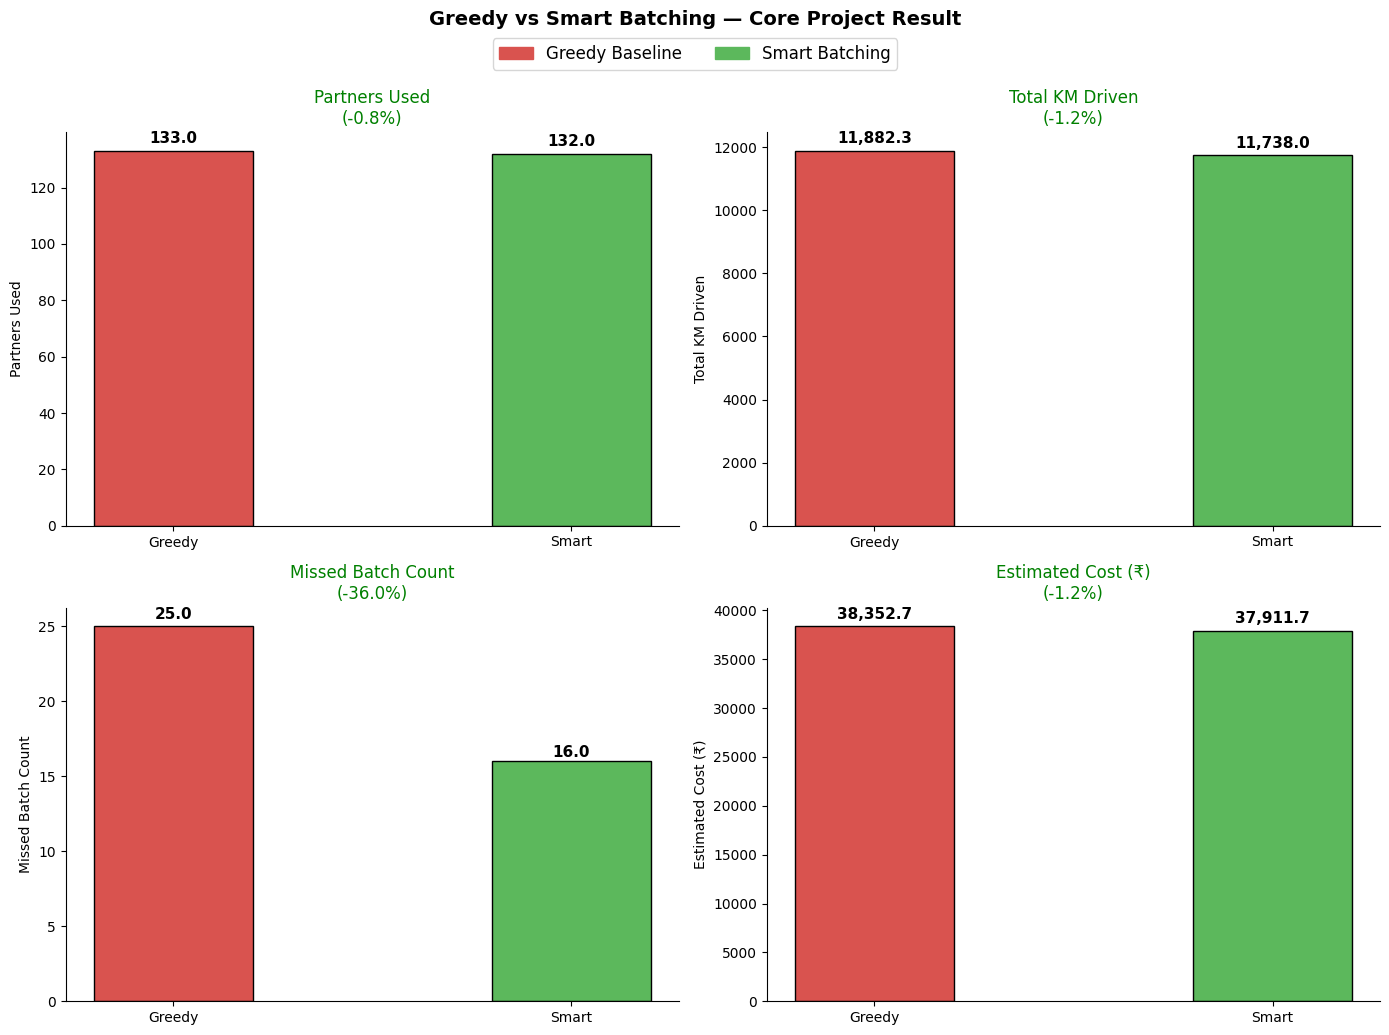


✅ Saved → results/core_result_comparison.png


In [48]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 4 key metrics plotted as side by side bars
# Each chart title shows the % improvement over greedy
plot_metrics = [
    ("Partners Used",      "total_partners_used", "total_partners_used"),
    ("Total KM Driven",    "total_km_driven",     "total_km_driven"),
    ("Missed Batch Count", "missed_batch_count",  "missed_batch_count"),
    ("Estimated Cost (₹)", "baseline_cost_inr",   "estimated_cost_inr"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (label, base_key, smart_key) in enumerate(plot_metrics):
    base_val  = baseline.get(base_key,  0)
    smart_val = smart.get(smart_key, 0)

    bars = axes[idx].bar(
        ["Greedy", "Smart"],
        [base_val, smart_val],
        color=["#d9534f", "#5cb85c"],
        edgecolor="black",
        width=0.4
    )

    # Value on top of each bar
    for bar, val in zip(bars, [base_val, smart_val]):
        axes[idx].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 1.02,
            f"{val:,.1f}",
            ha="center", fontsize=11, fontweight="bold"
        )

    # % change in chart title — green if improvement, red if worse
    if base_val > 0:
        delta_pct = (smart_val - base_val) / base_val * 100
        color     = "green" if delta_pct < 0 else "red"
        axes[idx].set_title(f"{label}\n({delta_pct:+.1f}%)", fontsize=12, color=color)
    else:
        axes[idx].set_title(label, fontsize=12)

    axes[idx].set_ylabel(label)
    axes[idx].spines["top"].set_visible(False)
    axes[idx].spines["right"].set_visible(False)

greedy_patch = mpatches.Patch(color="#d9534f", label="Greedy Baseline")
smart_patch  = mpatches.Patch(color="#5cb85c", label="Smart Batching")
fig.legend(handles=[greedy_patch, smart_patch], loc="upper center",
           ncol=2, fontsize=12, bbox_to_anchor=(0.5, 1.01))

plt.suptitle("Greedy vs Smart Batching — Core Project Result",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig("results/core_result_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n✅ Saved → results/core_result_comparison.png")